Name: Kashish Sharma

Roll no: 11

Section: C

Batch: C1

ML lab 7

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler , LabelEncoder
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (confusion_matrix ,
    accuracy_score ,
    precision_score ,
    recall_score ,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay)

pd.set_option("display.max_columns", None)

In [ ]:
df=pd.read_csv("bank_notes.csv")

In [ ]:
df.head()

,variance,skewness,curtosis,entropy,Target
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [ ]:
df.tail()

,variance,skewness,curtosis,entropy,Target
1367,0.40614,1.34920,-1.4501,-0.55949,1
1368,-1.38870,-4.87730,6.4774,0.34179,1
1369,-3.75030,-13.45860,17.5932,-2.77710,1
1370,-3.56370,-8.38270,12.3930,-1.28230,1
1371,-2.54190,-0.65804,2.6842,1.19520,1


In [ ]:
df.shape

(1372, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   Target    1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [ ]:
df.describe()

,variance,skewness,curtosis,entropy,Target
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.433735,2.842763,-7.0421,-1.773000,0.49618,2.821475,6.8248
skewness,1372.0,1.922353,5.869047,-13.7731,-1.708200,2.31965,6.814625,12.9516
curtosis,1372.0,1.397627,4.310030,-5.2861,-1.574975,0.61663,3.179250,17.9274
entropy,1372.0,-1.191657,2.101013,-8.5482,-2.413450,-0.58665,0.394810,2.4495
Target,1372.0,0.444606,0.497103,0.0000,0.000000,0.00000,1.000000,1.0000


In [ ]:
df.columns

Index(['variance', 'skewness', 'curtosis', 'entropy', 'Target'], dtype='object')

In [ ]:
df.isnull()

,variance,skewness,curtosis,entropy,Target
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
1367,False,False,False,False,False
1368,False,False,False,False,False
1369,False,False,False,False,False
1370,False,False,False,False,False


Bar plot


Text(0, 0.5, 'Count')

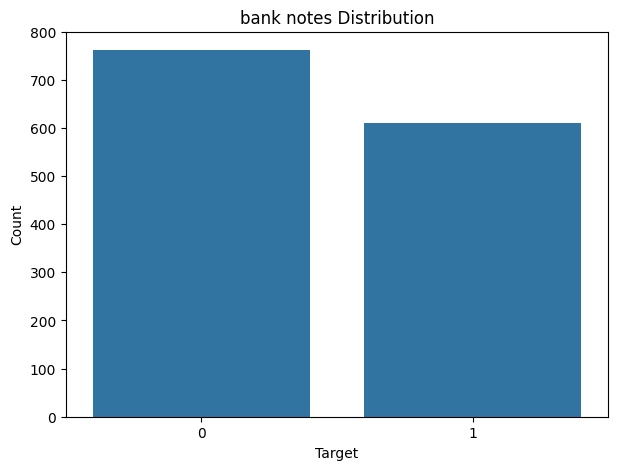

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(data=df , x="Target")

plt.title("bank notes Distribution")
plt.xlabel("Target")
plt.ylabel("Count")

Pie-Chart

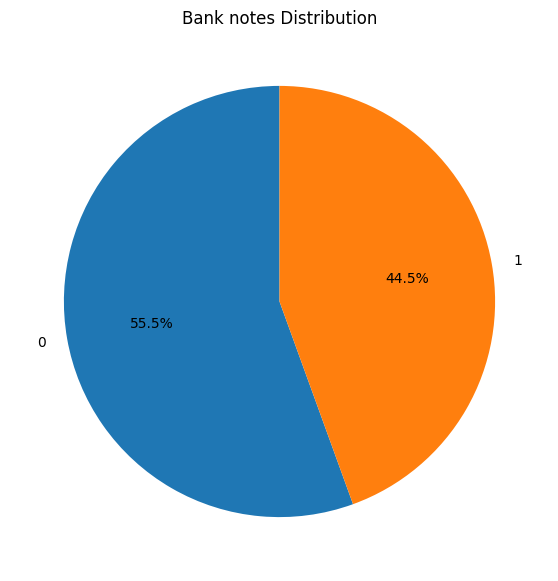

In [ ]:
class_count = df['Target'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(class_count, labels=class_count.index, autopct='%1.1f%%', startangle=90)
plt.title('Bank notes Distribution')
plt.show()

In [ ]:
numerical_features = df.select_dtypes(include=np.number).columns

print("Numerical features:")
print(numerical_features.tolist())

Numerical features:
['variance', 'skewness', 'curtosis', 'entropy', 'Target']


Histogram

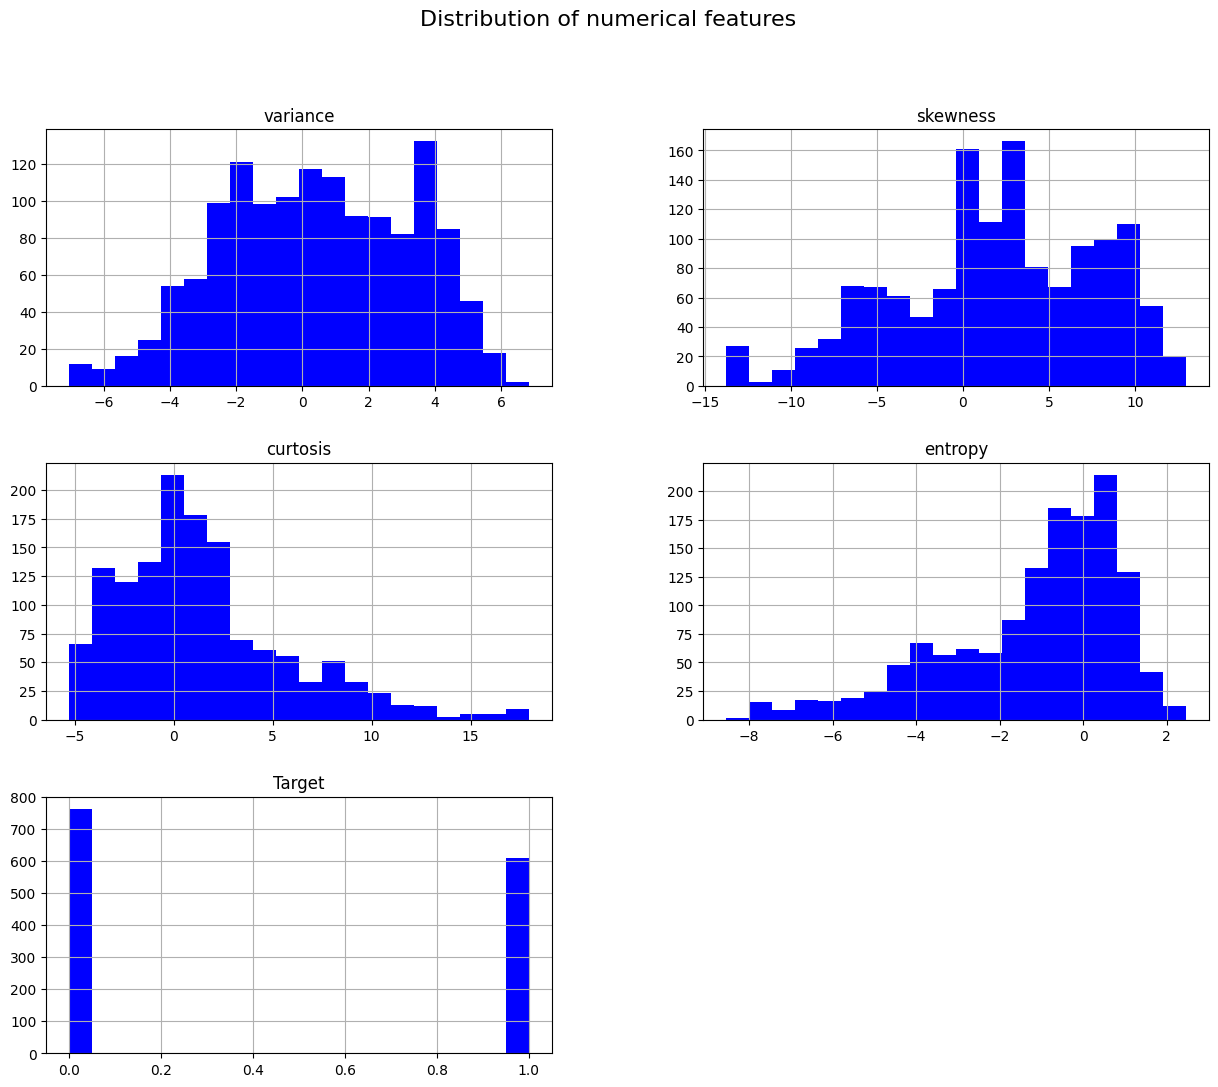

In [ ]:
df[numerical_features].hist(figsize=(15, 12),bins=20,color="blue")
plt.suptitle("Distribution of numerical features",fontsize=16)
plt.show()

Boxplot

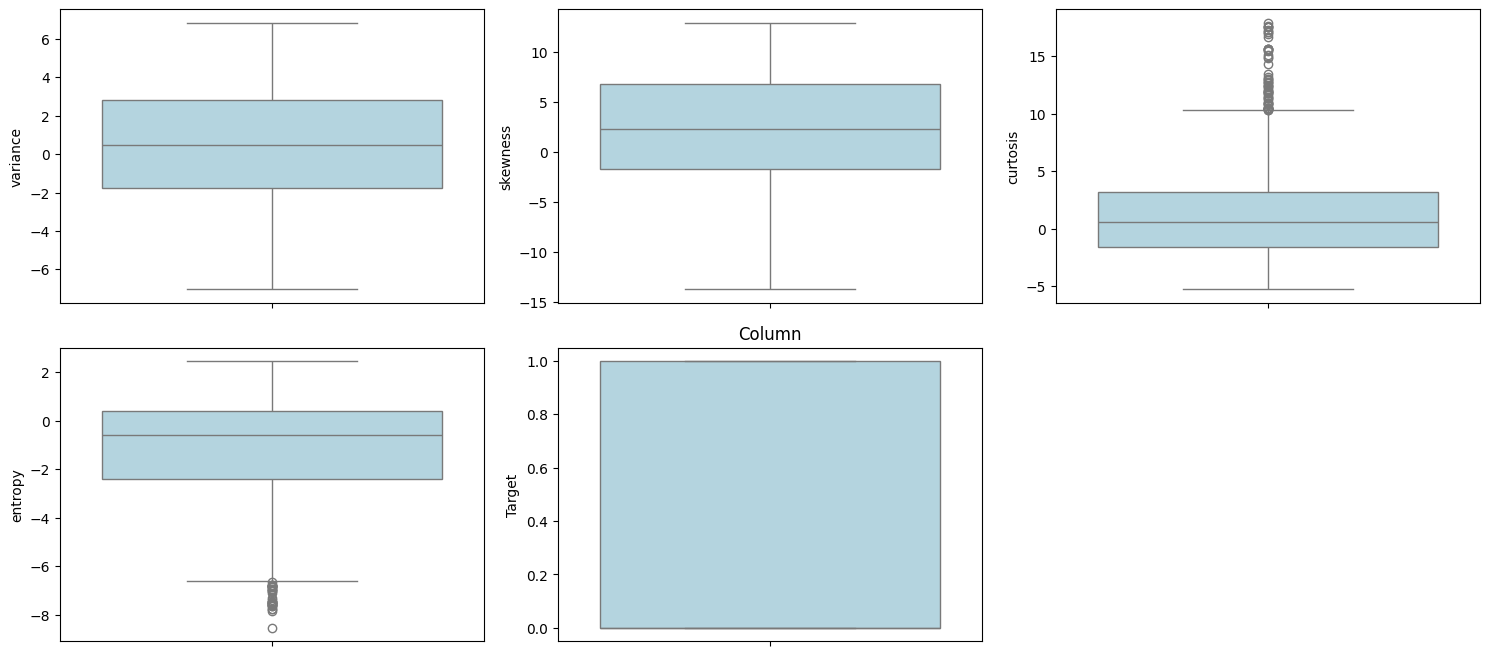

In [ ]:
plt.figure(figsize=(15, 10))

for i, column in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[column],color="lightblue")
plt.title("Column")
plt.tight_layout()
plt.show()

Historgram with kde Function

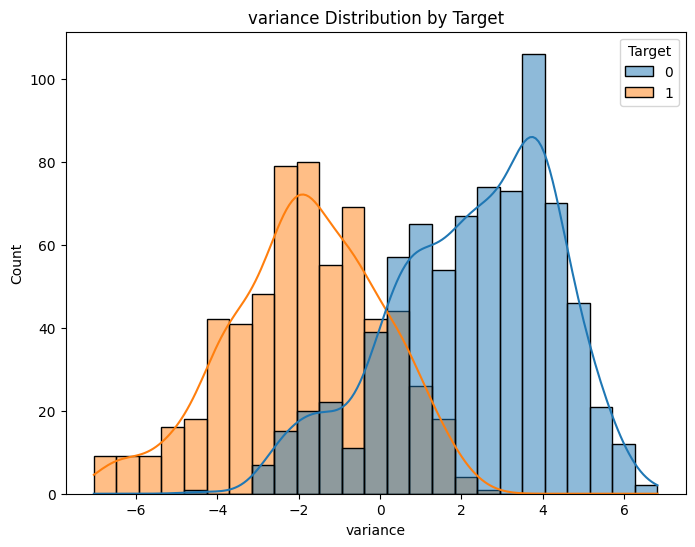

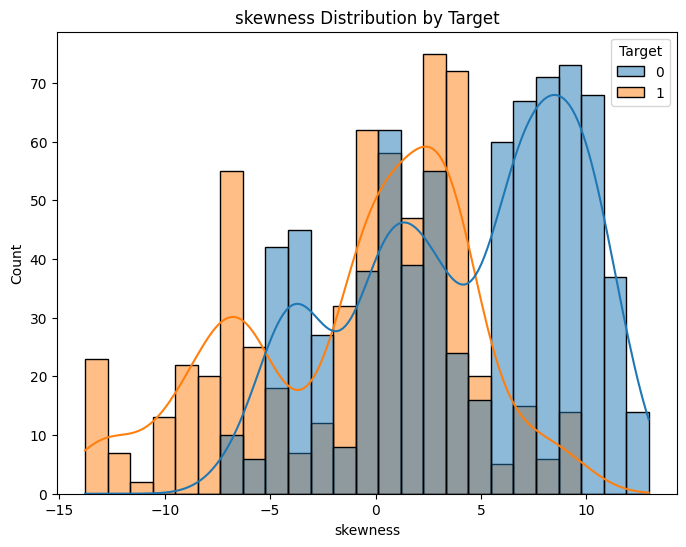

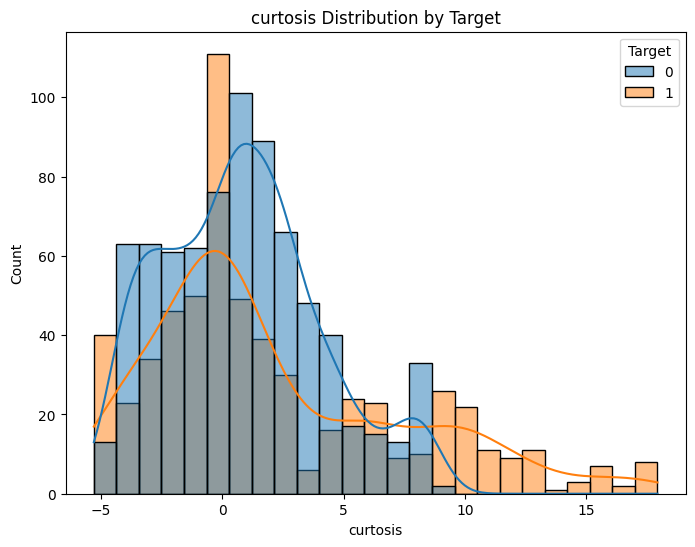

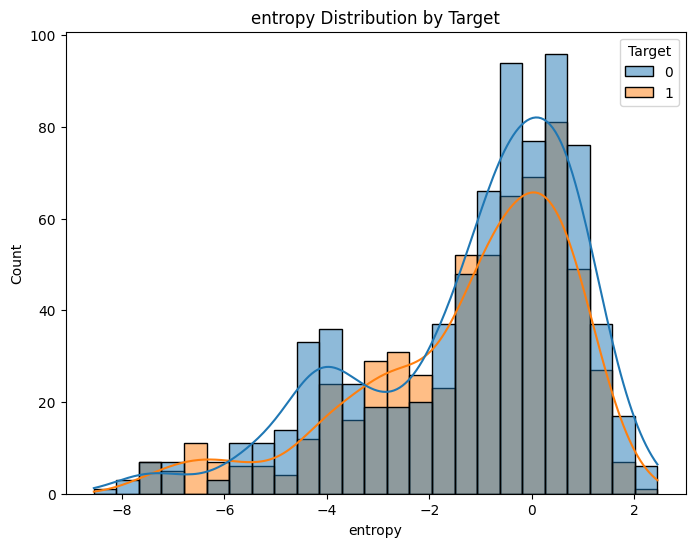

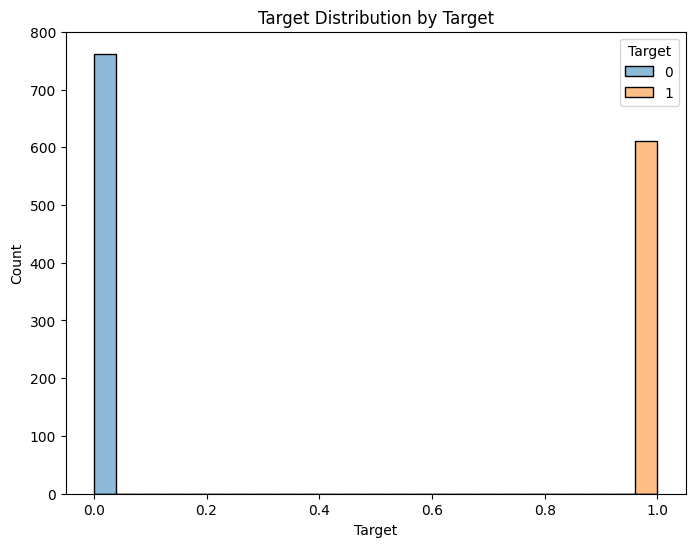

In [ ]:
for column in numerical_features:
    plt.figure(figsize=(8, 6))
    sns.histplot(data=df, x=column,hue="Target", kde=True, bins=25)
    plt.title(f'{column} Distribution by Target')
    plt.show()

Correlation Matrix

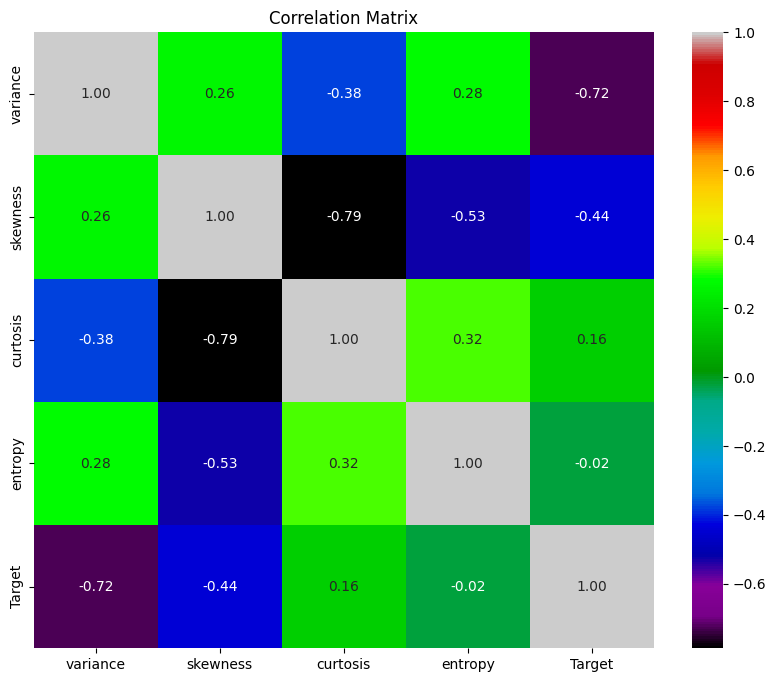

In [ ]:
correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='nipy_spectral', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()


Scatter plot



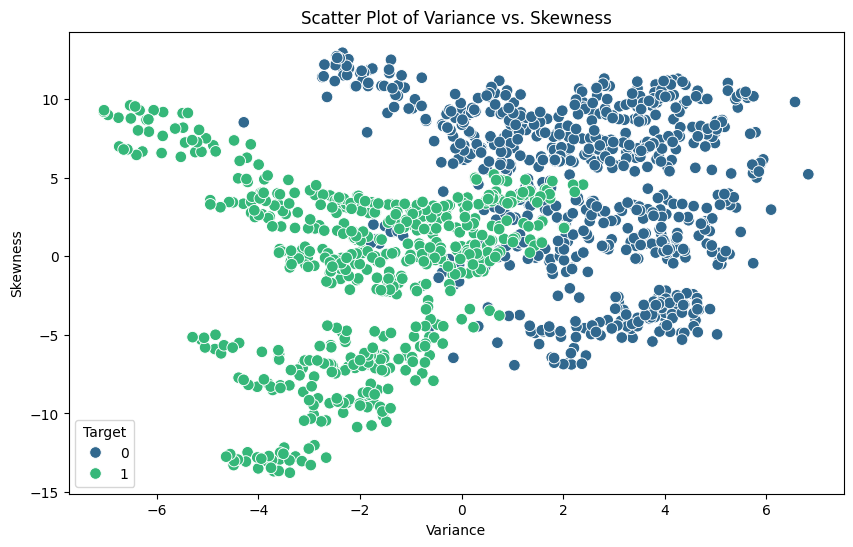

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='variance', y='skewness', hue='Target', palette='viridis', s=70)
plt.title('Scatter Plot of Variance vs. Skewness')
plt.xlabel('Variance')
plt.ylabel('Skewness')
plt.show()

In [ ]:
X = df.drop('Target', axis=1)
y = df.Target

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)
print("training samples:", X_train.shape[0])
print("testing samples:", X_test.shape[0])

training samples: 1097
testing samples: 275


In [ ]:
GaussianNB()

GaussianNB()

In [ ]:
gnb = GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [ ]:
y_pred = gnb.predict(X_test)
print("predicted labels:")
print(y_pred)

predicted labels:
[0 1 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 0 1 1 1 0
 1 0 0 1 1 1 0 1 1 0 0 0 1 1 0 1 0 1 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0
 1 0 1 0 0 1 1 0 1 1 0 1 0 1 1 1 0 1 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 1 1 1
 1 0 0 0 0 0 0 1 1 0 0 0 0 1 0 0 0 0 1 0 0 0 1 1 0 0 1 1 1 0 1 0 1 0 1 0 1
 0 0 1 0 1 1 0 0 1 0 1 0 1 0 0 1 0 0 1 1 0 0 1 1 0 0 1 1 1 0 0 1 0 0 0 0 0
 1 0 1 1 1 0 1 0 1 0 0 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 0 1 0 0
 1 0 0 0 1 1 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 1 0
 0 0 0 1 1 0 0 1 0 1 1 0 0 0 0 0]


In [ ]:
comparison = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(comparison.head(20))

      Actual  Predicted
385        0          0
899        1          1
47         0          0
1018       1          1
786        1          1
1346       1          1
645        0          0
32         0          0
200        0          0
887        1          1
646        0          0
1270       1          1
52         0          0
201        0          0
347        0          0
663        0          0
1166       1          1
956        1          1
767        1          1
134        0          0


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy (%):",accuracy * 100)

Accuracy: 1.0
Accuracy (%): 100.0


In [ ]:
precision = precision_score(y_test, y_pred)
print("Precision:", precision)
print("Precision (%):", precision * 100)

Precision: 1.0
Precision (%): 100.0


In [ ]:
recall = recall_score(y_test, y_pred)
print("Recall:", recall)


Recall: 1.0


In [ ]:
f1 = f1_score(y_test, y_pred)
print("F1 Score:", f1)

F1 Score: 1.0


In [ ]:
print("====Model profermance====")
print(f"Accuracy : {accuracy: .4f}")
print(f"Precision : {precision: .4f}")
print(f"Recall : {recall: .4f}")
print(f"F1 Score : {f1: .4f}")

====Model profermance====
Accuracy :  1.0000
Precision :  1.0000
Recall :  1.0000
F1 Score :  1.0000


In [ ]:
print("Classifiction Report")
print(classification_report(y_test,y_pred))

Classifiction Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       153
           1       1.00      1.00      1.00       122

    accuracy                           1.00       275
   macro avg       1.00      1.00      1.00       275
weighted avg       1.00      1.00      1.00       275



In [ ]:
from sklearn.metrics import accuracy_score

y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
print("Training Accuracy:", train_accuracy)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Testing Accuracy:", test_accuracy)


Training Accuracy: 1.0
Testing Accuracy: 1.0
